# Baseline CNN experiments: start simple, then improve

This notebook follows the development of our **SmallCNN and WideCNN** for 12-class thermal solar-module classification. It explains each choice, reads the evidence we have, and provides a controlled way to run the next experiment. ResNet and transfer learning belong in `03_resnet18_experiments.ipynb`.

**Reading order:** initial rationale → architecture and settings → majority baseline → initial trial → longer training → class weighting → wider CNN → extended learning-rate comparison → error analysis → next decisions.

**Before running:** activate this repository's `.venv`, install `requirements.txt`, and select that environment as the kernel. Complete the download, cleaning and frozen-split verification described in `data/README.md`. See `01_data_exploration.ipynb` for the dataset introduction. Run from the repository root or `notebooks/`.

Normal execution reads saved results and performs shape/data checks. It does **not** train full models or access test images. Full training requires an explicit call with `full=True`. Local checkpoints and predictions are ignored by Git; the tracked comparison JSON allows readers to inspect the recent results without those files.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import subprocess
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/pv_fault/models/baseline.py").is_file():
    raise RuntimeError("Run from the repository root or notebooks folder.")
sys.path.insert(0, str(ROOT / "src"))
from pv_fault.data import CLASS_NAMES, CLASS_TO_INDEX, SolarModuleDataset
from pv_fault.models.baseline import SmallCNN, WideCNN
from pv_fault.evaluate import classification_metrics

SEED = 2112
MANIFEST = ROOT / "data/splits/infrared_solar_modules_v1.csv"
manifest = pd.read_csv(MANIFEST, dtype=str)
manifest_summary = json.loads(MANIFEST.with_suffix(".json").read_text())
assert hashlib.sha256(MANIFEST.read_bytes()).hexdigest() == manifest_summary["manifest_sha256"]
assert manifest.groupby("group_id")["split"].nunique().eq(1).all()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Split assignments and group separation checked. No test images loaded.")

from pv_fault.plots import learning_curves, confusion_matrix, image_examples


Split assignments and group separation checked. No test images loaded.


## 1. Why begin with SmallCNN?

Our first question was: **can a small model trained from scratch learn useful fault patterns better than a predictor that always chooses the most common class?**

We chose SmallCNN because:

- **It matches the input:** one grayscale channel at the native 40×24 resolution; no unnecessary RGB conversion or enlargement.
- **Convolutions suit the task:** small filters can learn local brightness patterns and combine them into image features.
- **It is cheap to run:** 38,412 trainable parameters make repeated local-CPU experiments feasible.
- **It is easy to diagnose:** few layers make it easier to check shapes, training behaviour and implementation mistakes.
- **It provides a reference:** a more complicated model must demonstrate a useful improvement over this starting point.

This is a simple, conventional starting architecture, not a pretrained model with the layers being chosen by us. Familiar optimiser defaults reduce the number of initial choices; they do not establish an optimal configuration. We train from scratch with PyTorch's layer initialisation.


In [2]:
torch.manual_seed(SEED)
small = SmallCNN(num_classes=len(CLASS_NAMES))
wide = WideCNN(num_classes=len(CLASS_NAMES))
print(small)
architecture_sizes = pd.DataFrame([
    {"Model": "SmallCNN", "Trainable parameters": sum(p.numel() for p in small.parameters())},
    {"Model": "WideCNN", "Trainable parameters": sum(p.numel() for p in wide.parameters())},
]).set_index("Model")
display(architecture_sizes)
assert architecture_sizes.loc["SmallCNN", "Trainable parameters"] == 38412
assert architecture_sizes.loc["WideCNN", "Trainable parameters"] == 338316


SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=512, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=12, bias=True)
  )
)


,Trainable parameters
Model,
SmallCNN,38412
WideCNN,338316


### How an image moves through SmallCNN

| Step | Shape for one image | Purpose |
|---|---|---|
| Grayscale input | `1 × 40 × 24` | Native image, with pixels scaled to 0–1 |
| 3×3 convolution + ReLU | `16 × 40 × 24` | Learn 16 local feature patterns |
| 2×2 max pooling | `16 × 20 × 12` | Reduce spatial size |
| 3×3 convolution + ReLU | `32 × 20 × 12` | Combine features into 32 patterns |
| 2×2 max pooling | `32 × 10 × 6` | Reduce spatial size again |
| Adaptive average pooling | `32 × 4 × 4` | Produce a fixed feature-grid size |
| Flatten → linear → ReLU | `512 → 64` | Combine image features |
| Final linear layer | `12` | One score for each class |

These final scores are **logits**, not probabilities. Cross-entropy accepts logits directly; softmax is used when saving probability-like scores. The highest score determines the predicted class. A correct anomaly category is required for 12-class accuracy: predicting `Cell` for `Cracking` is still an error.


## 2. Our original settings and their justification

We begin with the settings actually recorded in the first experiment plan, rather than retrospectively starting with the best settings. **The first run had no class weighting.** We introduced weighting later.

- **Adam, learning rate 0.001:** a conventional starting optimiser; 0.001 is Adam's default learning rate. Momentum coefficients and epsilon also use PyTorch defaults.
- **Unweighted cross-entropy:** a standard starting loss for mutually exclusive classes; later weighting addresses the observed imbalance.
- **Batch size 64:** a practical starting compromise between update frequency and CPU/memory use, not a tuned optimum.
- **At most five epochs:** an inexpensive first learning check, not a claim that the network can converge in five epochs.
- **Early-stopping patience two:** initially limited wasted computation; later trials relaxed this.
- **Seed 2112:** makes the setup reproducible within the same environment. One seed does not measure variability.
- **No augmentation, dropout, batch normalisation or pretrained features:** keeps the initial model easy to interpret and gives later changes a clear reference.

Backpropagation (`loss.backward()`) computes gradients; Adam (`optimizer.step()`) updates weights. These already happen in the shared training code, not as additional optimisation tricks.


In [3]:
PLAN_FILES = {
    "initial_small": "experiment-plan.json",
    "longer_small": "experiment-plan-v2.json",
    "weighted_small": "experiment-plan-v3.json",
    "weighted_wide": "experiment-plan-v4.json",
    "extended_small_001": "experiment-plan-smallcnn-extended-lr1e-3.json",
    "extended_small_0003": "experiment-plan-smallcnn-extended-lr3e-4.json",
    "extended_wide_001": "experiment-plan-widecnn-extended-lr1e-3.json",
    "extended_wide_0003": "experiment-plan-widecnn-extended-lr3e-4.json",
}
plans = {key: json.loads((ROOT / "configs" / filename).read_text())
         for key, filename in PLAN_FILES.items()}
settings = []
for stage, plan in plans.items():
    settings.append({"Stage": stage, "Model": plan.get("model", "small_cnn"),
                     "Learning rate": plan["learning_rate"], "Batch": plan["batch_size"],
                     "Max epochs": plan["max_epochs"], "Patience": plan["early_stopping_patience"],
                     "Time cap (s)": plan["max_elapsed_seconds"],
                     "Loss weighting": plan.get("class_weighting", "none")})
display(pd.DataFrame(settings).set_index("Stage"))
assert all(plan["manifest_sha256"] == manifest_summary["manifest_sha256"] for plan in plans.values())


,Model,Learning rate,Batch,Max epochs,Patience,Time cap (s),Loss weighting
Stage,,,,,,,
initial_small,small_cnn,0.0010,64,5,2,120,none
longer_small,small_cnn,0.0010,64,15,2,60,none
weighted_small,small_cnn,0.0010,64,15,2,60,sqrt_inverse_frequency
weighted_wide,wide_cnn,0.0010,64,15,2,120,sqrt_inverse_frequency
extended_small_001,small_cnn,0.0010,64,30,5,300,sqrt_inverse_frequency
extended_small_0003,small_cnn,0.0003,64,30,5,300,sqrt_inverse_frequency
extended_wide_001,wide_cnn,0.0010,64,30,5,300,sqrt_inverse_frequency
extended_wide_0003,wide_cnn,0.0003,64,30,5,300,sqrt_inverse_frequency


## 3. Establish a baseline that does not learn

Before judging the CNN, choose the most common class using **training labels only** and predict it for every validation image. Validation labels are used only to score those predictions. Counts from the manifest are sufficient; no test images or test metrics are needed.

The majority predictor can get approximately 50% accuracy by always saying `No-Anomaly`. It misses every anomaly. We therefore select CNN checkpoints by **validation macro-F1**, while also reporting accuracy, per-class recall, faults called normal and normal false alarms.


In [4]:
training_rows = manifest.loc[manifest["split"].eq("train")]
validation_rows = manifest.loc[manifest["split"].eq("val")]
counts = training_rows["label"].value_counts()
majority = max(CLASS_NAMES, key=lambda name: (counts.get(name, 0), -CLASS_TO_INDEX[name]))
y_true = [CLASS_TO_INDEX[label] for label in validation_rows["label"]]
majority_metrics = classification_metrics(y_true, [CLASS_TO_INDEX[majority]] * len(y_true))
display(pd.DataFrame([{
    "Predictor": f"Always {majority}", "Validation accuracy": majority_metrics["accuracy"],
    "Validation macro-F1": majority_metrics["macro_f1"],
    "Faults called normal": majority_metrics["faults_called_normal"],
    "Normal false alarms": majority_metrics["normal_called_fault"],
}]).set_index("Predictor").round(4))


,Validation accuracy,Validation macro-F1,Faults called normal,Normal false alarms
Predictor,,,,
Always No-Anomaly,0.5007,0.0556,1492,0


## 4. Check the pipeline, then run the initial experiment

A shape check establishes that the existing loader and model agree. It does **not** establish that an untrained model can classify faults. The following cell uses training images only and loads no validation/test pixels. If local images are absent, it prints setup instructions and skips the image check.

The training script offers a two-batch smoke check before a full trial. Full training uses the original training partition for updates and validation for checkpoint selection, and refuses to overwrite an existing run. The notebook calls that script instead of implementing another training loop.


In [5]:
if (ROOT / "data/processed/near_clean/module_metadata.json").is_file():
    train_dataset = SolarModuleDataset("train", manifest=MANIFEST)
    loader = DataLoader(train_dataset, batch_size=64, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    images, labels = next(iter(loader))
    small.eval()
    with torch.inference_mode():
        logits = small(images)
    print("Images:", tuple(images.shape), "Labels:", tuple(labels.shape), "Class scores:", tuple(logits.shape))
    print("Example numeric label:", labels[0].item(), "=", CLASS_NAMES[labels[0].item()])
    assert tuple(logits.shape) == (len(labels), len(CLASS_NAMES))
else:
    print("Shape check skipped: prepare the cleaned local dataset using data/README.md.")


Images: (64, 1, 40, 24) Labels: (64,) Class scores: (64, 12)
Example numeric label: 2 = Cracking


In [6]:
def run_experiment(stage, *, full=False):
    """Run a chosen plan through the shared entry point; never overwrite a run."""
    if stage not in PLAN_FILES:
        raise ValueError(f"Choose a stage from {tuple(PLAN_FILES)}")
    command = [sys.executable, str(ROOT / "scripts/train_baseline.py"),
               "--plan", str(ROOT / "configs" / PLAN_FILES[stage])]
    if full:
        verification = subprocess.run(
            [sys.executable, str(ROOT / "scripts/create_split.py"), "--verify-only"],
            cwd=ROOT, capture_output=True, text=True)
        if verification.returncode:
            raise RuntimeError(verification.stdout + verification.stderr)
        print(verification.stdout)
        command.append("--full")
    environment = dict(os.environ, PYTHONPATH=str(ROOT / "src"))
    subprocess.run(command, cwd=ROOT, env=environment, check=True)

# Explicit actions: uncomment ONE when you want to run it.
# run_experiment("initial_small")              # Two-batch smoke check only.
# run_experiment("initial_small", full=True)   # Original bounded training trial.
# Existing run directories are preserved; do not delete them just to rerun.
print("No training launched. Uncomment an explicit experiment call when ready.")


No training launched. Uncomment an explicit experiment call when ready.


### What evidence survives from the initial run?

`experiment-plan-v2.json` records the previous five-epoch run's macro-F1 and fault-to-normal rate. Its full checkpoint/history was not available in this checkout. We display those values as **historical recorded evidence**, not as a newly executed or independently verified trial. The original run's accuracy was not retained in that record, so we leave it missing rather than infer it.


In [7]:
prior = plans["longer_small"]["prior_run"]
display(pd.DataFrame([
    {"Evidence": "Majority predictor (computed above)", "Epochs": 0,
     "Validation macro-F1": majority_metrics["macro_f1"],
     "Faults called normal (%)": 100 * majority_metrics["fault_to_normal_rate"]},
    {"Evidence": "Initial SmallCNN (historical plan record)", "Epochs": prior["epochs"],
     "Validation macro-F1": prior["best_validation_macro_f1"],
     "Faults called normal (%)": 100 * prior["fault_to_normal_rate"]},
]).set_index("Evidence").round(3))


,Epochs,Validation macro-F1,Faults called normal (%)
Evidence,,,
Majority predictor (computed above),0,0.056,100.000
Initial SmallCNN (historical plan record),5,0.109,86.059


## 5. First progression: allow learning, then address imbalance

**Longer SmallCNN trial:** increase the planned maximum from five to 15 epochs, holding model, learning rate and unweighted loss fixed. This asks whether the first run was simply too short. However, its time cap changed too, so the full protocol is not a strictly single-variable comparison. The complete V2 results are unavailable locally; the plan is evidence of what was intended, not proof of an improvement.

**Weighted SmallCNN trial:** keep the same architecture but introduce class weights proportional to `1 / sqrt(training class count)`, normalised to average one. Rare classes contribute more strongly to training loss. Weights come from training labels only; validation metrics remain unweighted.

The historical weighted SmallCNN report gives **58.67% accuracy, 0.3318 macro-F1, 336/1,492 faults called normal and 336/1,496 normal false alarms**. These are reported outcomes, not full locally recovered run artifacts. Without complete V2 outputs we cannot isolate how much of that result is attributable to weighting.

A tiny-subset overfit diagnostic is also available in `scripts/check_cnn_overfit.py`. It tests whether the model and optimiser can memorise a small training-only sample. It is a pipeline diagnostic, not a generalisation result; no result is claimed here without its output.


## 6. Second progression: increase capacity with WideCNN

WideCNN keeps the same sequence of operations and two convolution layers. It increases convolution channels from **16/32 to 64/128** and classifier hidden width from **64 to 128**, increasing parameters from **38,412 to 338,316**.

**Hypothesis:** greater capacity may improve class discrimination. More parameters also increase computation and do not guarantee fewer missed faults.

The historical comparison reported the following. The wider run completed 14 epochs before its time cap, so this was not an equal-completed-epoch comparison. Its full artifacts are absent here; use the tracked report as the source.


In [8]:
historical = pd.DataFrame([
    {"Model": "Weighted SmallCNN V3", "Accuracy": 0.5867, "Macro-F1": 0.3318,
     "Faults called normal": 336, "Normal false alarms": 336},
    {"Model": "Weighted WideCNN V1", "Accuracy": 0.6583, "Macro-F1": 0.3975,
     "Faults called normal": 458, "Normal false alarms": 136},
]).set_index("Model")
display(historical)
display(Markdown("Source: [historical width comparison](../results/widecnn-v1-validation.md). "
                 "**Widening improved macro-F1 but increased missed faults.** "
                 "This trade-off motivates reporting more than accuracy."))


,Accuracy,Macro-F1,Faults called normal,Normal false alarms
Model,,,,
Weighted SmallCNN V3,0.5867,0.3318,336,336
Weighted WideCNN V1,0.6583,0.3975,458,136


Source: [historical width comparison](../results/widecnn-v1-validation.md). **Widening improved macro-F1 but increased missed faults.** This trade-off motivates reporting more than accuracy.

## 7. Recent controlled comparison: training duration and learning rate

We ran four fresh trials: both architectures at **0.001 and 0.0003**, each with at most 30 epochs, early-stopping patience five and a 300-second cap. Batch 64, seed 2112, class weighting and architecture were fixed. No augmentation, scheduler or regularisation changes were added.

These are recorded validation experiments, not models retrained by this cell. All four completed 30 epochs. To study additional training, we also compare the best score through epoch 15 with the best score in the **same run**. This avoids treating historical experiments from a different environment as controlled reruns.

The tracked comparison JSON contains learning histories, metrics and provenance, so these plots work without local checkpoint files. We check its manifest fingerprint and reported counts before displaying results.


In [9]:
comparison_path = ROOT / "results/cnn-training-comparison-v1.json"
if not comparison_path.is_file():
    raise FileNotFoundError("Missing tracked CNN comparison JSON; include it with this notebook.")
experiments = json.loads(comparison_path.read_text())
rows = []
for item in experiments:
    provenance, metrics, summary = item["provenance"], item["metrics"], item["summary"]
    assert provenance["manifest_sha256"] == manifest_summary["manifest_sha256"]
    assert metrics["count"] == len(validation_rows)
    assert summary["test_evaluated"] is False and summary["checkpoint_predictions_verified"]
    assert provenance["train_images"] == len(training_rows)
    rows.append({"Run": item["run_id"], "Model": item["model"], "Learning rate": item["learning_rate"],
                 "Epochs completed": summary["epochs_completed"], "Best epoch": summary["best_epoch"],
                 "Validation accuracy": metrics["accuracy"], "Validation macro-F1": metrics["macro_f1"],
                 "Faults called normal": metrics["faults_called_normal"],
                 "Normal false alarms": metrics["normal_called_fault"]})
comparison = pd.DataFrame(rows).set_index("Run")
display(comparison.round(4))
print("All four recorded checkpoints reproduced their saved validation predictions in the run environment.")
print("This cell checks the result record; it does not reload unavailable checkpoints or rerun training.")


,Model,Learning rate,Epochs completed,Best epoch,Validation accuracy,Validation macro-F1,Faults called normal,Normal false alarms
Run,,,,,,,,
smallcnn-extended-lr1e-3-s2112-v1,small_cnn,0.0010,30,29,0.6412,0.4224,343,245
smallcnn-extended-lr3e-4-s2112-v1,small_cnn,0.0003,30,29,0.5927,0.2935,537,201
widecnn-extended-lr1e-3-s2112-v1,wide_cnn,0.0010,30,27,0.6914,0.5114,258,199
widecnn-extended-lr3e-4-s2112-v1,wide_cnn,0.0003,30,30,0.6463,0.4106,368,204


All four recorded checkpoints reproduced their saved validation predictions in the run environment.
This cell checks the result record; it does not reload unavailable checkpoints or rerun training.


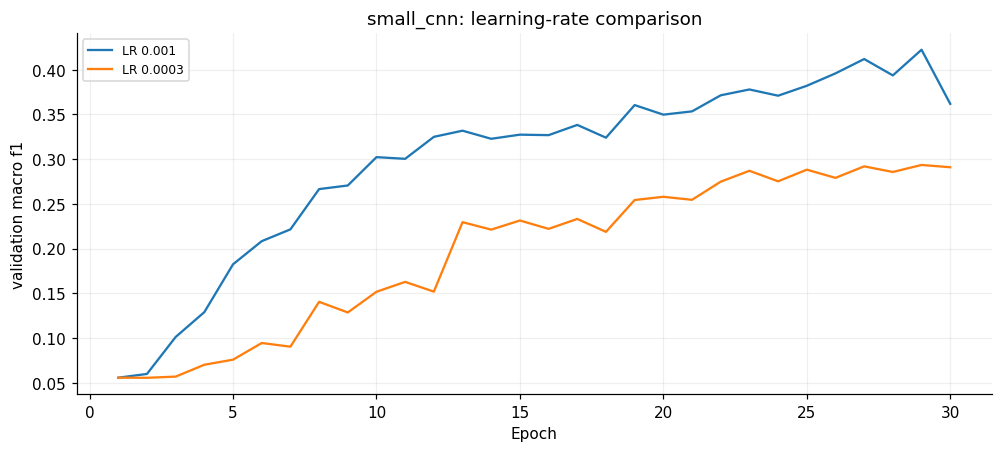

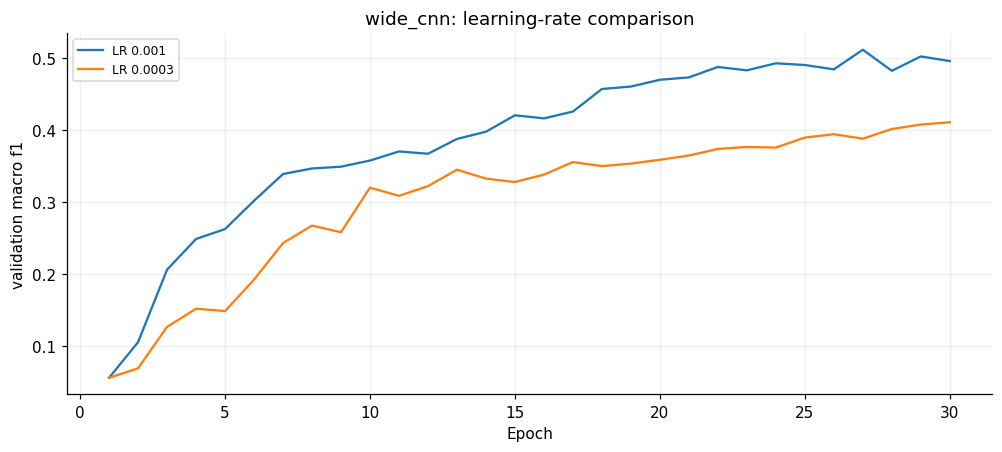

In [10]:
for model in ("small_cnn", "wide_cnn"):
    runs = [run for run in experiments if run["model"] == model]
    learning_curves(runs, title=f"{model}: learning-rate comparison",
                    labels=[f"LR {run['learning_rate']:g}" for run in runs])


In [11]:
progress = []
for item in experiments:
    before = max(entry["validation_macro_f1"] for entry in item["history"] if entry["epoch"] <= 15)
    after = item["metrics"]["macro_f1"]
    progress.append({"Model": item["model"], "Learning rate": item["learning_rate"],
                     "Best macro-F1 through epoch 15": before, "Best through epoch 30": after,
                     "Difference": after - before,
                     "Selected training accuracy": item["selected_training_fit"]["accuracy"],
                     "Selected validation accuracy": item["metrics"]["accuracy"]})
display(pd.DataFrame(progress).round(4))


,Model,Learning rate,Best macro-F1 through epoch 15,Best through epoch 30,Difference,Selected training accuracy,Selected validation accuracy
0,small_cnn,0.0010,0.3318,0.4224,0.0905,0.6451,0.6412
1,small_cnn,0.0003,0.2314,0.2935,0.0621,0.5961,0.5927
2,wide_cnn,0.0010,0.4203,0.5114,0.0911,0.7049,0.6914
3,wide_cnn,0.0003,0.3446,0.4106,0.0660,0.6522,0.6463


### Decisions supported by those results

- **Keep 0.001 as the current reference rate:** it outperformed 0.0003 for both architectures within the tested 30-epoch budget. This does not mean 0.0003 could never improve with more training.
- **The initial training budget was restrictive:** at 0.001, extending the same trajectories past epoch 15 improved SmallCNN macro-F1 from 0.3318 to 0.4224 and WideCNN from 0.4203 to 0.5114.
- **At this stage, WideCNN was the stronger CNN:** at 0.001 it reached 69.14% accuracy and 0.5114 macro-F1, with 258 faults called normal. SmallCNN remains a useful lightweight reference.
- **Do not assume convergence:** all four runs stopped at the epoch limit. Their best checkpoints were selected between epochs 27 and 30.
- **Do not assume strong overfitting:** the restored 0.001 models have small training–validation accuracy gaps. That does not exclude class-specific overfitting. Online training accuracy in the plots is measured while weights change; the table's selected-training accuracy evaluates the restored checkpoint.

Training loss is class-weighted and validation loss is unweighted, so we do not plot them as directly comparable losses. More detailed provenance and caveats are in [the comparison report](../results/cnn-training-comparison-v1.md).


## 8. Look beyond the headline score

Compare the best recorded configuration **within each architecture**, selected by validation macro-F1. Per-class recall asks: of the images truly belonging to this category, what fraction did we recognise correctly? The confusion matrix below uses true labels on rows and predictions on columns, with each row normalised to sum to one.

This is validation-based error analysis, not another test-set evaluation.


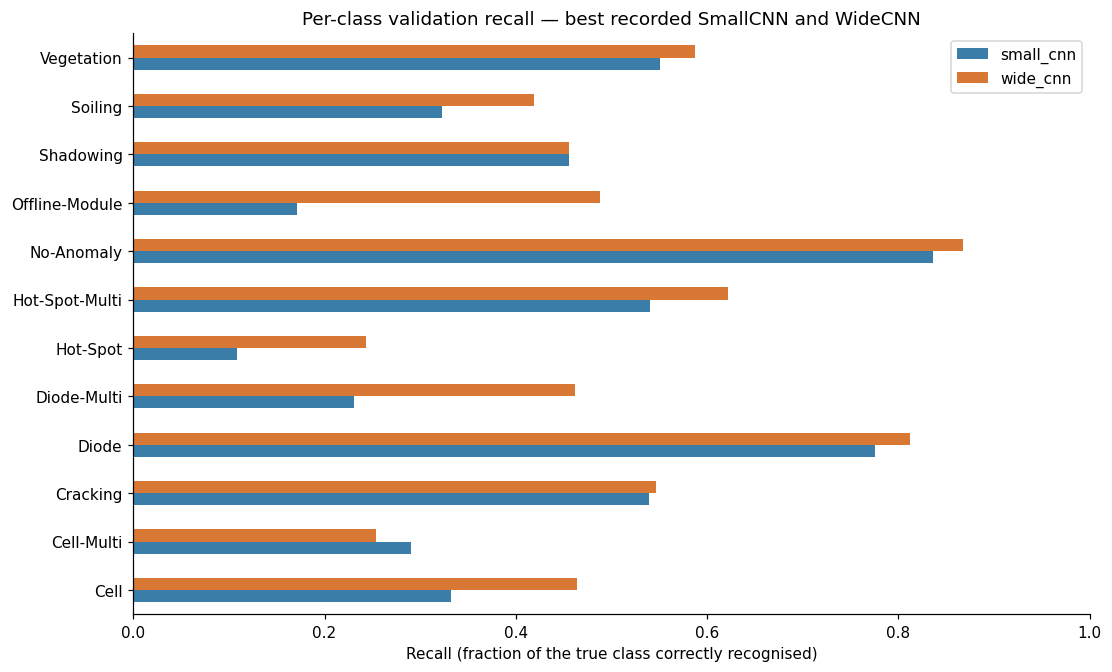

,small_cnn,wide_cnn
Cell,0.332,0.464
Cell-Multi,0.290,0.254
Cracking,0.539,0.546
Diode,0.776,0.812
Diode-Multi,0.231,0.462
Hot-Spot,0.108,0.243
Hot-Spot-Multi,0.541,0.622
No-Anomaly,0.836,0.867
Offline-Module,0.171,0.488
Shadowing,0.455,0.455


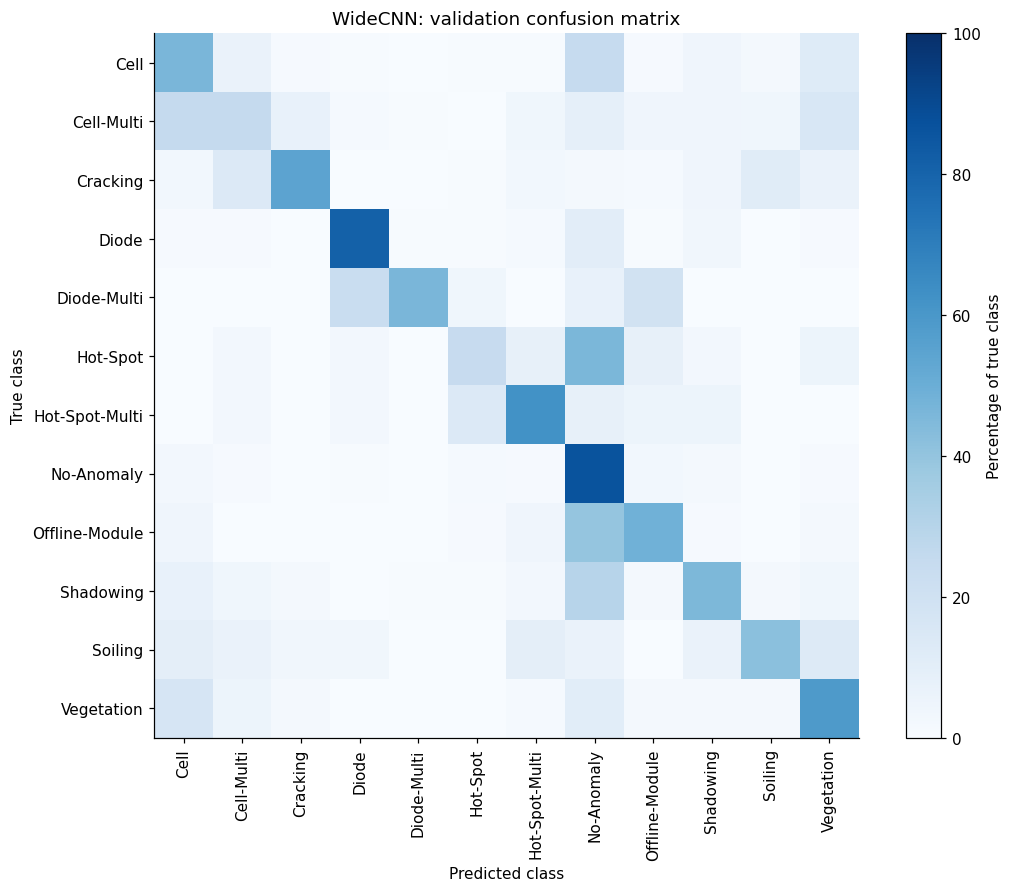

<Axes: title={'center': 'WideCNN: validation confusion matrix'}, xlabel='Predicted class', ylabel='True class'>

In [12]:
best_by_model = {model: max((item for item in experiments if item["model"] == model),
                            key=lambda item: item["metrics"]["macro_f1"])
                 for model in ("small_cnn", "wide_cnn")}
recall = pd.DataFrame({model: {name: item["metrics"]["per_class"][name]["recall"] for name in CLASS_NAMES}
                       for model, item in best_by_model.items()}).reindex(CLASS_NAMES)
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
recall.plot.barh(ax=ax, color=["#397da8", "#d97835"])
ax.set(xlabel="Recall (fraction of the true class correctly recognised)", ylabel="", xlim=(0, 1),
       title="Per-class validation recall — best recorded SmallCNN and WideCNN")
plt.show()
display(recall.round(3))

chosen = best_by_model["wide_cnn"]
confusion_matrix(chosen["metrics"], "WideCNN: validation confusion matrix")


### Interpretation

WideCNN still has weak recall for `Cell-Multi` (about 25%) and `Hot-Spot` (about 24%). It calls 258/1,492 anomalous validation images normal and sends 199/1,496 normal images into anomaly categories. A better macro-F1 does not remove this trade-off. Review class confusion and representative validation errors before attributing failures to network size alone.

A model prediction is one label per image. It is not an expert diagnosis, repair recommendation, electrical-safety clearance or reuse decision.


## 9. Scheduler and batch-normalisation experiments — progress log

**Decision before running:** keep Adam, batch 64, initial learning rate 0.001, the frozen split, class-weighted loss, seed 2112 and four CPU threads. Test a scheduler and BatchNorm **separately** for each CNN; do not combine changes before measuring them individually.

| Arm | Change from its 0.001 reference | Hypothesis |
|---|---|---|
| Control | Existing 30-epoch, constant-rate model | Retain the previous result as the reference |
| Scheduler only | Reduce LR by a factor of 0.3 after two consecutive epochs that fail to beat the best validation macro-F1; minimum LR 0.00001 | Smaller later updates may refine the solution |
| BatchNorm only | Insert BatchNorm after each convolution and before ReLU; keep LR constant | Normalising intermediate features may make optimisation easier |

Each new trial permits at most 30 epochs, five non-improving epochs and 300 seconds checked between epochs. Post-training checkpoint verification adds overhead. The scheduler uses PyTorch patience 1, which triggers after **two** bad epochs. Early stopping remains at patience five, leaving some opportunity after a reduction. A schedule that never reduces LR has not tested the benefit of smaller later updates.

BatchNorm estimates statistics from training batches and learns channel scale/offset. Evaluation uses stored running statistics; tests check that validation does not modify them. The original convolution biases are retained so that only BatchNorm is added. Convolution and classifier initial weights match the corresponding control under the same seed. BatchNorm increases parameter counts to **38,508** and **338,700**; it is optional and off by default.

The controls were run immediately before this extension in the same environment. Their default architecture and training path are preserved; they are not additional reruns. Code fingerprints differ because optional features have now been implemented. This is a single-seed exploratory validation comparison, not a final test result.


In [13]:
ablation_plans = []
for size in ("small", "wide"):
    for variant in ("scheduler", "batchnorm"):
        stage = f"{size}_{variant}"
        filename = f"experiment-plan-{size}cnn-{variant}.json"
        PLAN_FILES[stage] = filename
        plan = json.loads((ROOT / "configs" / filename).read_text())
        plans[stage] = plan
        ablation_plans.append({"Stage": stage, "Run": plan["run_id"],
                               "BatchNorm": plan["batch_norm"], "Scheduler": plan["scheduler"],
                               "Initial LR": plan["learning_rate"], "Epoch cap": plan["max_epochs"],
                               "Patience": plan["early_stopping_patience"], "Time cap (s)": plan["max_elapsed_seconds"]})
display(pd.DataFrame(ablation_plans).set_index("Stage"))
# Explicit examples; do not rerun a completed run ID.
# run_experiment("small_scheduler")              # smoke check
# run_experiment("small_scheduler", full=True)   # bounded full trial
# run_experiment("small_batchnorm", full=True)
# run_experiment("wide_scheduler", full=True)
# run_experiment("wide_batchnorm", full=True)


,Run,BatchNorm,Scheduler,Initial LR,Epoch cap,Patience,Time cap (s)
Stage,,,,,,,
small_scheduler,smallcnn-scheduler-s2112-v1,False,plateau,0.001,30,5,300
small_batchnorm,smallcnn-batchnorm-s2112-v1,True,none,0.001,30,5,300
wide_scheduler,widecnn-scheduler-s2112-v1,False,plateau,0.001,30,5,300
wide_batchnorm,widecnn-batchnorm-s2112-v1,True,none,0.001,30,5,300


### Recorded progress and outcomes

The following cells read a shareable result snapshot rather than launching training. A missing snapshot means the trials are still pending or the result file has not been added to the checkout. Missing results are never treated as zero scores.

Judge each variant against its **own architecture's control** using macro-F1, missed faults and normal false alarms. Inspect epoch counts and LR reductions: a time-capped or early-stopped run does not have the same number of optimisation steps as a complete run.


In [14]:
ablation_path = ROOT / "results/cnn-scheduler-batchnorm-v1.json"
ablation_experiments = []
if ablation_path.is_file():
    ablation_experiments = json.loads(ablation_path.read_text())
    ablation_rows = []
    controls = {model: next(item for item in experiments
                           if item["model"] == model and item["learning_rate"] == 0.001)
                for model in ("small_cnn", "wide_cnn")}
    for model, item in controls.items():
        metrics = item["metrics"]
        ablation_rows.append({"Model": model, "Arm": "Control", "Accuracy": metrics["accuracy"],
            "Macro-F1": metrics["macro_f1"], "Change in macro-F1": 0.0,
            "Faults called normal": metrics["faults_called_normal"], "Normal false alarms": metrics["normal_called_fault"],
            "Epochs / best": f"{item['summary']['epochs_completed']} / {item['summary']['best_epoch']}",
            "LR reductions": 0, "Stop": item["summary"]["stop_reason"]})
    for item in ablation_experiments:
        assert item["provenance"]["manifest_sha256"] == manifest_summary["manifest_sha256"]
        assert item["summary"]["test_evaluated"] is False
        metrics, summary = item["metrics"], item["summary"]
        reductions = sum(entry["next_learning_rate"] < entry["learning_rate"] for entry in item["history"])
        ablation_rows.append({"Model": item["model"], "Arm": item["variant"], "Accuracy": metrics["accuracy"],
            "Macro-F1": metrics["macro_f1"], "Change in macro-F1": metrics["macro_f1"] - controls[item["model"]]["metrics"]["macro_f1"],
            "Faults called normal": metrics["faults_called_normal"], "Normal false alarms": metrics["normal_called_fault"],
            "Epochs / best": f"{summary['epochs_completed']} / {summary['best_epoch']}",
            "LR reductions": reductions, "Stop": summary["stop_reason"]})
    ablation_table = pd.DataFrame(ablation_rows).sort_values(["Model", "Arm"])
    display(ablation_table.set_index(["Model", "Arm"]).round(4))
else:
    print("Scheduler/BatchNorm snapshot is pending; no results claimed yet.")


Accuracy  Macro-F1  Change in macro-F1  \
Model     Arm                                                 
small_cnn Control      0.6412    0.4224              0.0000   
          batchnorm    0.6523    0.4888              0.0664   
          scheduler    0.6222    0.3667             -0.0556   
wide_cnn  Control      0.6914    0.5114              0.0000   
          batchnorm    0.6727    0.5051             -0.0063   
          scheduler    0.7011    0.5209              0.0095   

                     Faults called normal  Normal false alarms Epochs / best  \
Model     Arm                                                                  
small_cnn Control                     343                  245       30 / 29   
          batchnorm                   152                  349       18 / 13   
          scheduler                   404                  219       30 / 28   
wide_cnn  Control                     258                  199       30 / 27   
          batchnorm                   129                  334       18 / 13   
          scheduler                   287                  181       30 / 27   

                     LR reductions            Stop  
Model     Arm                                       
small_cnn Control                0      max_epochs  
          batchnorm              0  early_stopping  
          scheduler              4      max_epochs  
wide_cnn  Control                0      max_epochs  
          batchnorm              0  early_stopping  
          scheduler              2      max_epochs

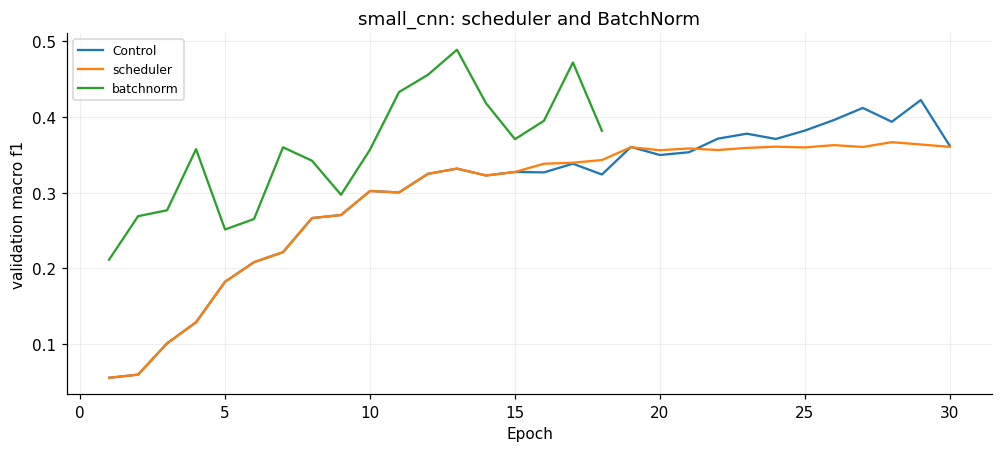

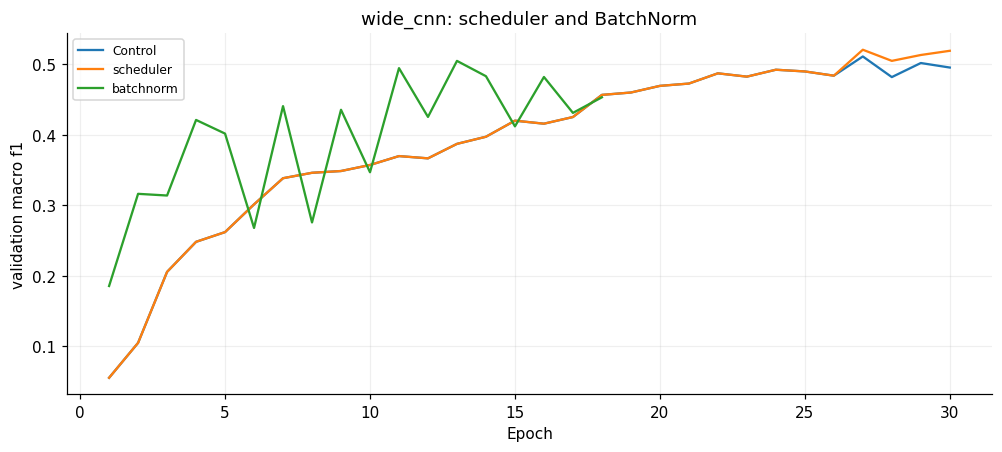

In [15]:
if ablation_experiments:
    for model in ("small_cnn", "wide_cnn"):
        arms = [controls[model]] + [r for r in ablation_experiments if r["model"] == model]
        learning_curves(arms, title=f"{model}: scheduler and BatchNorm",
                        labels=["Control"] + [r["variant"] for r in arms[1:]])


### SGD and GELU: candidates, not completed experiments

We **already use mini-batches of 64**, currently with Adam. Mini-batching is not an additional SGD-only technique. Switching to SGD with momentum would change the optimiser. It can work well for CNNs, but needs its own learning-rate and schedule comparison; using Adam's selected rate by default would not establish SGD's potential.

GELU is a smooth activation, `x × Φ(x)`, unlike ReLU's hard zero cutoff for negative inputs. It changes activation/gradient behaviour and adds no trainable parameters. It may help or hurt this small thermal classifier; smoothness alone does not establish an improvement. Test a ReLU-to-GELU swap separately under a fixed protocol before combining it with other changes.

Neither SGD nor GELU was run in this four-trial comparison. Technical references: [PyTorch SGD](https://docs.pytorch.org/docs/2.8/generated/torch.optim.SGD.html), [GELU](https://docs.pytorch.org/docs/2.8/generated/torch.nn.GELU.html), and [ReduceLROnPlateau](https://docs.pytorch.org/docs/2.8/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html).


## 10. Timed optimisation search — 23 October 2026

**User-requested budget:** 45 minutes, from 15:54:52 to 16:39:52 Sydney time. This section extends the initial four ablations with a bounded, adaptive search. We prioritise validation macro-F1 while retaining accuracy, balanced accuracy, per-class recall, faults called normal and normal false alarms. The original test set remains unused.

### Choices made before observing the new candidates

- Keep the frozen split, batch 64, training-only class weights and primary seed 2112. No paid compute. Each candidate has an explicit plan, maximum 30 epochs, patience five and a 300-second time cap checked between epochs.
- Start from BatchNorm for the new activation/depth/optimiser arms, and compare each with its same-architecture BatchNorm reference. Keep the original constant-rate and scheduler results visible too.
- **GELU:** replace ReLU in the convolution blocks and hidden classifier, without changing widths. This is a test of the activation, not an assumed improvement.
- **Extra convolution:** insert one same-channel 3×3 convolution before adaptive pooling, with the selected activation and BatchNorm. Do not add another downsampling step or enlarge the classifier. This adds depth and parameters.
- **AdamW:** test weight decay 0.0001. This changes the declared optimiser/regularisation setup; it is not a perfectly isolated test of decay alone.
- **SGD with momentum:** compare initial rates 0.01 and 0.03 with momentum 0.9, keeping batch 64. This is still mini-batch training, as with Adam. It is a limited rate comparison, not exhaustive tuning of SGD.
- Try an adaptive GELU+depth combination only if both individually outperform the BatchNorm reference and enough time remains. Distinguish adaptive choices from the initial list.
- Reserve time to check the best configurations with seed 42 and to document results. Unrun/interrupted candidates are listed honestly; there is no need to fill every planned slot.

Full source snapshots accompany new local checkpoints. Earlier experiments retain their original fingerprints. A checkpoint must be reconstructed with its recorded `batch_norm`, `activation` and `extra_conv` flags; the defaults remain the original two-layer ReLU networks.

This search reuses validation to make many decisions, so the highest score is an optimistic development estimate. A second seed tests sensitivity, not independent generalisation. The test set is reserved for the final frozen protocol.

**Outcome of this budget:** GELU and extra depth were tested for both architectures. The deeper WideCNN trial hit the external time guard; its saved best checkpoint was subsequently verified without further training. Treat that score as a **recovered provisional checkpoint**, not a complete 30-epoch result. AdamW, SGD-rate, combination and seed-42 plans were not run in the remaining budget. The ledger records those omissions; they have no scores. No replication or stability claim is made for the selected candidates.


In [16]:
search_path = ROOT / "results/cnn-search-45min-v1.json"
search_experiments = []
if search_path.is_file():
    search_snapshot = json.loads(search_path.read_text())
    assert search_snapshot["test_evaluated"] is False
    search_experiments = search_snapshot["experiments"]
    search_rows = []
    for item in search_experiments:
        metrics, plan = item["metrics"], item["plan"]
        assert item["summary"]["checkpoint_predictions_verified"]
        assert item["summary"]["test_evaluated"] is False
        assert item["provenance"]["manifest_sha256"] == manifest_summary["manifest_sha256"]
        label = item["run_id"].split("cnn-", 1)[1].rsplit("-s", 1)[0]
        search_rows.append({"Model": item["model"], "Configuration": label, "Seed": item["seed"],
            "Macro-F1": metrics["macro_f1"], "Accuracy": metrics["accuracy"],
            "Balanced accuracy": metrics["balanced_accuracy"],
            "Faults called normal": metrics["faults_called_normal"],
            "Normal false alarms": metrics["normal_called_fault"],
            "Epochs": item["summary"]["epochs_completed"], "Run status": item["summary"]["stop_reason"]})
    search_table = pd.DataFrame(search_rows).sort_values(["Model", "Seed", "Macro-F1"], ascending=[True, True, False])
    display(search_table.set_index(["Model", "Configuration", "Seed"]).round(4))
    print("Snapshot updated (UTC):", search_snapshot["updated_utc"])
    ledger = search_snapshot.get("ledger") or {}
    if ledger.get("trials"):
        display(pd.DataFrame([{key: row.get(key) for key in ("run_id", "phase", "status")}
                              for row in ledger["trials"]]).set_index("run_id"))
else:
    print("Timed search snapshot not yet available; no result is implied for any planned candidate.")


Macro-F1  Accuracy  Balanced accuracy  \
Model     Configuration   Seed                                          
small_cnn search-bn-depth 2112    0.5964    0.7413             0.6183   
          search-bn-gelu  2112    0.5549    0.7216             0.5512   
          batchnorm       2112    0.4888    0.6523             0.5324   
          extended-lr1e-3 2112    0.4224    0.6412             0.4293   
          scheduler       2112    0.3667    0.6222             0.3750   
          extended-lr3e-4 2112    0.2935    0.5927             0.3035   
wide_cnn  search-bn-depth 2112    0.5500    0.7313             0.5637   
          scheduler       2112    0.5209    0.7011             0.5168   
          extended-lr1e-3 2112    0.5114    0.6914             0.5183   
          search-bn-gelu  2112    0.5095    0.6954             0.5283   
          batchnorm       2112    0.5051    0.6727             0.5627   
          extended-lr3e-4 2112    0.4106    0.6463             0.4082   

                                Faults called normal  Normal false alarms  \
Model     Configuration   Seed                                              
small_cnn search-bn-depth 2112                    82                  240   
          search-bn-gelu  2112                   272                  125   
          batchnorm       2112                   152                  349   
          extended-lr1e-3 2112                   343                  245   
          scheduler       2112                   404                  219   
          extended-lr3e-4 2112                   537                  201   
wide_cnn  search-bn-depth 2112                   149                  179   
          scheduler       2112                   287                  181   
          extended-lr1e-3 2112                   258                  199   
          search-bn-gelu  2112                   233                  180   
          batchnorm       2112                   129                  334   
          extended-lr3e-4 2112                   368                  204   

                                Epochs  \
Model     Configuration   Seed           
small_cnn search-bn-depth 2112      30   
          search-bn-gelu  2112      17   
          batchnorm       2112      18   
          extended-lr1e-3 2112      30   
          scheduler       2112      30   
          extended-lr3e-4 2112      30   
wide_cnn  search-bn-depth 2112      13   
          scheduler       2112      30   
          extended-lr1e-3 2112      30   
          search-bn-gelu  2112      13   
          batchnorm       2112      18   
          extended-lr3e-4 2112      30   

                                                                       Run status  
Model     Configuration   Seed                                                     
small_cnn search-bn-depth 2112                                         max_epochs  
          search-bn-gelu  2112                                     early_stopping  
          batchnorm       2112                                     early_stopping  
          extended-lr1e-3 2112                                         max_epochs  
          scheduler       2112                                         max_epochs  
          extended-lr3e-4 2112                                         max_epochs  
wide_cnn  search-bn-depth 2112  external_guard_interrupted_then_checkpoint_ver...  
          scheduler       2112                                         max_epochs  
          extended-lr1e-3 2112                                         max_epochs  
          search-bn-gelu  2112                                     early_stopping  
          batchnorm       2112                                     early_stopping  
          extended-lr3e-4 2112                                         max_epochs

Snapshot updated (UTC): 2026-10-23T05:38:24.471454+00:00


,phase,status
run_id,,
smallcnn-search-bn-gelu-s2112-v1,single_change,completed
widecnn-search-bn-gelu-s2112-v1,single_change,completed
smallcnn-search-bn-depth-s2112-v1,single_change,completed
widecnn-search-bn-depth-s2112-v1,single_change,interrupted_checkpoint_recovered_and_verified
smallcnn-search-bn-adamw-s2112-v1,single_change,not_run_budget_reserved
widecnn-search-bn-adamw-s2112-v1,single_change,not_run_budget_reserved
smallcnn-search-bn-sgd01-s2112-v1,single_change,not_run_budget_reserved
widecnn-search-bn-sgd01-s2112-v1,single_change,not_run_budget_reserved
smallcnn-search-bn-sgd03-s2112-v1,single_change,not_run_budget_reserved


Run  \
Model     Role                                                                                
small_cnn Original 30-epoch control                       smallcnn-extended-lr1e-3-s2112-v1   
          Best search candidate (selected on validation)  smallcnn-search-bn-depth-s2112-v1   
wide_cnn  Original 30-epoch control                        widecnn-extended-lr1e-3-s2112-v1   
          Best search candidate (selected on validation)   widecnn-search-bn-depth-s2112-v1   

                                                          Macro-F1  Accuracy  \
Model     Role                                                                 
small_cnn Original 30-epoch control                         0.4224    0.6412   
          Best search candidate (selected on validation)    0.5964    0.7413   
wide_cnn  Original 30-epoch control                         0.5114    0.6914   
          Best search candidate (selected on validation)    0.5500    0.7313   

                                                          Faults called normal  \
Model     Role                                                                   
small_cnn Original 30-epoch control                                        343   
          Best search candidate (selected on validation)                    82   
wide_cnn  Original 30-epoch control                                        258   
          Best search candidate (selected on validation)                   149   

                                                          Normal false alarms  
Model     Role                                                                 
small_cnn Original 30-epoch control                                       245  
          Best search candidate (selected on validation)                  240  
wide_cnn  Original 30-epoch control                                       199  
          Best search candidate (selected on validation)                  179

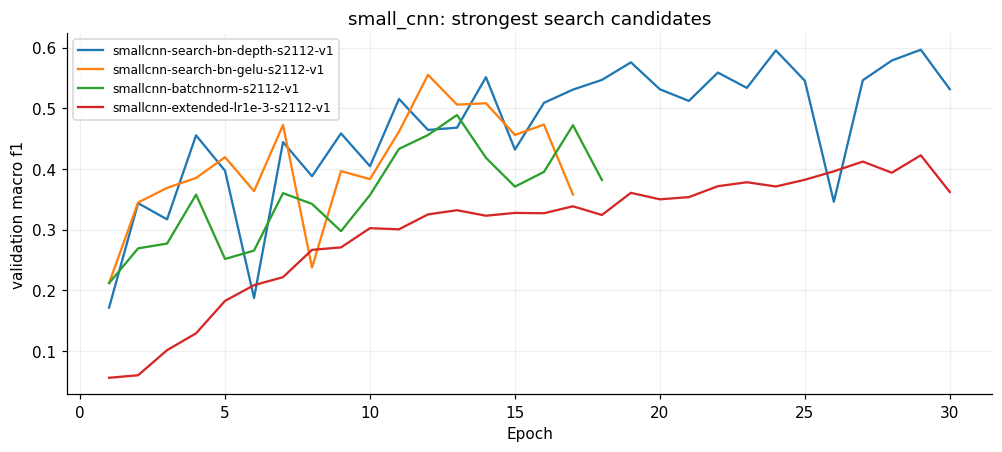

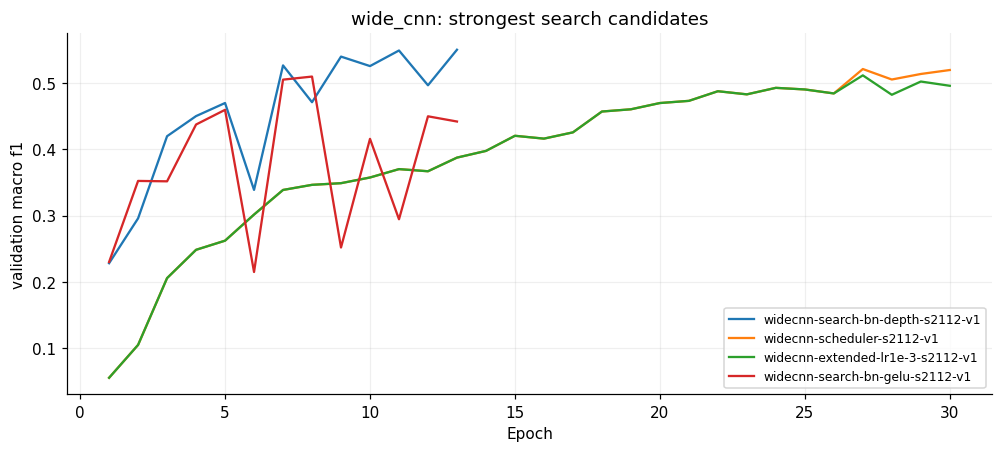

In [17]:
if search_experiments:
    # Compare the best development candidate from each architecture with its original control.
    primary_best = {model: max((item for item in search_experiments
                                if item["model"] == model and item["seed"] == 2112),
                               key=lambda item: item["metrics"]["macro_f1"])
                    for model in ("small_cnn", "wide_cnn")}
    summary_rows = []
    for model, item in primary_best.items():
        control = next(entry for entry in experiments if entry["model"] == model and entry["learning_rate"] == 0.001)
        for kind, result in (("Original 30-epoch control", control), ("Best search candidate (selected on validation)", item)):
            metrics = result["metrics"]
            summary_rows.append({"Model": model, "Role": kind, "Run": result["run_id"],
                                 "Macro-F1": metrics["macro_f1"], "Accuracy": metrics["accuracy"],
                                 "Faults called normal": metrics["faults_called_normal"],
                                 "Normal false alarms": metrics["normal_called_fault"]})
    display(pd.DataFrame(summary_rows).set_index(["Model", "Role"]).round(4))
    for model in ("small_cnn", "wide_cnn"):
        candidates = sorted([r for r in search_experiments if r["model"] == model and r["seed"] == 2112],
                            key=lambda r: r["metrics"]["macro_f1"], reverse=True)[:4]
        learning_curves(candidates, title=f"{model}: strongest search candidates")


### Decision log and seed checks

The next cell explains the strongest recorded configurations and lists any second-seed checks. A candidate is selected on macro-F1, but its missed-fault/false-alarm trade-off remains explicit. Do not silently replace the original baselines or claim that an untested combination is the winner.


In [18]:
if search_experiments:
    for model, item in primary_best.items():
        control = next(entry for entry in experiments if entry["model"] == model and entry["learning_rate"] == 0.001)
        m, c = item["metrics"], control["metrics"]
        display(Markdown(
            f"**{model}: {item['run_id']}** — validation macro-F1 **{m['macro_f1']:.4f}** "
            f"({m['macro_f1'] - c['macro_f1']:+.4f} versus the original control), "
            f"accuracy **{m['accuracy']:.1%}**, missed faults **{m['faults_called_normal']}/1,492**, "
            f"normal false alarms **{m['normal_called_fault']}/1,496**. "
            f"Stopped after {item['summary']['epochs_completed']} epochs "
            f"({item['summary']['stop_reason']}); selected epoch {item['summary']['best_epoch']}."
        ))
        plan = item["plan"]
        print({key: plan.get(key, default) for key, default in
               (("batch_norm", False), ("activation", "relu"), ("extra_conv", False),
                ("optimizer", "adam"), ("learning_rate", 0.001), ("weight_decay", 0.0), ("scheduler", "none"))})
    second_seed = search_table.loc[search_table["Seed"].eq(42)]
    if len(second_seed):
        display(Markdown("**Seed 42 checks:** these measure sensitivity to another initialisation/shuffle. "
                         "If there is no matching control at seed 42, this is not a paired estimate of improvement."))
        display(second_seed.set_index(["Model", "Configuration", "Seed"]).round(4))
    else:
        print("No completed seed-42 confirmation is recorded yet.")


**small_cnn: smallcnn-search-bn-depth-s2112-v1** — validation macro-F1 **0.5964** (+0.1740 versus the original control), accuracy **74.1%**, missed faults **82/1,492**, normal false alarms **240/1,496**. Stopped after 30 epochs (max_epochs); selected epoch 29.

{'batch_norm': True, 'activation': 'relu', 'extra_conv': True, 'optimizer': 'adam', 'learning_rate': 0.001, 'weight_decay': 0.0, 'scheduler': 'none'}


**wide_cnn: widecnn-search-bn-depth-s2112-v1** — validation macro-F1 **0.5500** (+0.0386 versus the original control), accuracy **73.1%**, missed faults **149/1,492**, normal false alarms **179/1,496**. Stopped after 13 epochs (external_guard_interrupted_then_checkpoint_verified); selected epoch 13.

{'batch_norm': True, 'activation': 'relu', 'extra_conv': True, 'optimizer': 'adam', 'learning_rate': 0.001, 'weight_decay': 0.0, 'scheduler': 'none'}
No completed seed-42 confirmation is recorded yet.


## 11. Optimiser follow-up: AdamW and mini-batch SGD

**User decision:** test the previously unrun optimiser candidates now, without additional seeds. This is a follow-up to the closed 45-minute search; its old “unrun” ledger remains an accurate historical record.

For each CNN, compare these on the **two-convolution BatchNorm + ReLU architecture**:

| Arm | Learning rate | Other setting | Why test it? |
|---|---|---|---|
| Prior Adam control | 0.001 | No weight decay | Matched architecture reference |
| AdamW | 0.001 | Weight decay 0.0001 | Test an alternative optimiser/regularisation setup |
| SGD | 0.01 | Momentum 0.9 | Test a different gradient update rule at one candidate rate |
| SGD | 0.03 | Momentum 0.9 | Check sensitivity to a second, larger rate |

Keep batch 64, seed 2112, class-weighted loss, no augmentation/scheduler, maximum 30 epochs, patience five and 300-second cap. The small CNN has 38,508 parameters; the wide one 338,700. Momentum carries some previous update direction forward. AdamW adds decoupled weight decay; this changes more than the optimiser's name, so we do not attribute an outcome to a single mechanism.

The deeper models remain performance references but are **not matched controls** for these optimiser arms. Do not claim that changing optimiser caused a difference between differently deep networks. The test partition remains unused, and no seed checks are run.

**Completed follow-up:** all six trials ran, using seed 2112 throughout. Every saved checkpoint reproduced its validation predictions. The result tables below compare all error measures; no additional seeds or test-set evaluation were performed. See [the optimiser report](../results/cnn-optimizers-v1.md) for the compact record.


In [19]:
# Register follow-up plans with the shared run_experiment helper.
for size in ("small", "wide"):
    for arm in ("adamw", "sgd01", "sgd03"):
        stage = f"{size}_optimizer_{arm}"
        filename = f"experiment-plan-{size}cnn-optimizer-{arm}.json"
        PLAN_FILES[stage] = filename
        plans[stage] = json.loads((ROOT / "configs" / filename).read_text())
# Completed run IDs are preserved; uncommenting a full rerun will refuse overwrite.
# run_experiment("small_optimizer_sgd01")  # two-batch smoke check only

optimizer_path = ROOT / "results/cnn-optimizers-v1.json"
optimizer_experiments = []
if optimizer_path.is_file():
    optimizer_snapshot = json.loads(optimizer_path.read_text())
    assert optimizer_snapshot["test_evaluated"] is False
    assert optimizer_snapshot["seed_checks_performed"] is False
    optimizer_experiments = optimizer_snapshot["experiments"]
    optimizer_controls = optimizer_snapshot["controls"]
    optimizer_rows = []
    for label, result in [("Adam control", r) for r in optimizer_controls] + [(r["arm"], r) for r in optimizer_experiments]:
        p, m, s = result["plan"], result["metrics"], result["summary"]
        optimizer_rows.append({"Model": result["model"], "Arm": label, "LR": p["learning_rate"],
            "Macro-F1": m["macro_f1"], "Accuracy": m["accuracy"], "Balanced accuracy": m["balanced_accuracy"],
            "Missed faults": m["faults_called_normal"], "Normal false alarms": m["normal_called_fault"],
            "Epochs / best": f"{s['epochs_completed']} / {s['best_epoch']}", "Stop": s["stop_reason"]})
    display(pd.DataFrame(optimizer_rows).set_index(["Model", "Arm"]).round(4))
    display(pd.DataFrame([{key: trial.get(key) for key in ("run_id", "status")}
                          for trial in optimizer_snapshot["ledger"]["trials"]]).set_index("run_id"))
else:
    print("Optimiser follow-up pending; no result claimed yet.")


LR  Macro-F1  Accuracy  Balanced accuracy  \
Model     Arm                                                          
small_cnn Adam control  0.001    0.4888    0.6523             0.5324   
wide_cnn  Adam control  0.001    0.5051    0.6727             0.5627   
small_cnn adamw         0.001    0.4609    0.6647             0.4701   
          sgd01         0.010    0.5010    0.6961             0.4818   
          sgd03         0.030    0.4312    0.6573             0.4023   
wide_cnn  adamw         0.001    0.5179    0.6784             0.5528   
          sgd01         0.010    0.4253    0.6473             0.4432   
          sgd03         0.030    0.4280    0.6687             0.4276   

                        Missed faults  Normal false alarms Epochs / best  \
Model     Arm                                                              
small_cnn Adam control            152                  349       18 / 13   
wide_cnn  Adam control            129                  334       18 / 13   
small_cnn adamw                   278                  209       17 / 12   
          sgd01                   328                  135       17 / 12   
          sgd03                   448                  149       16 / 11   
wide_cnn  adamw                   137                  304       18 / 13   
          sgd01                   351                  234        13 / 8   
          sgd03                   340                  146       18 / 13   

                                  Stop  
Model     Arm                           
small_cnn Adam control  early_stopping  
wide_cnn  Adam control  early_stopping  
small_cnn adamw         early_stopping  
          sgd01         early_stopping  
          sgd03         early_stopping  
wide_cnn  adamw         early_stopping  
          sgd01         early_stopping  
          sgd03         early_stopping

,status
run_id,
smallcnn-optimizer-adamw-s2112-v1,completed
smallcnn-optimizer-sgd01-s2112-v1,completed
smallcnn-optimizer-sgd03-s2112-v1,completed
widecnn-optimizer-adamw-s2112-v1,completed
widecnn-optimizer-sgd01-s2112-v1,completed
widecnn-optimizer-sgd03-s2112-v1,completed


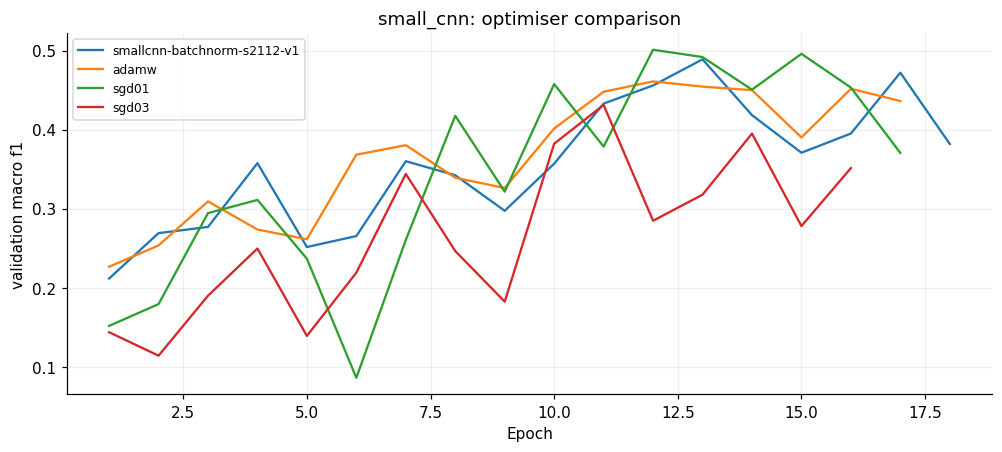

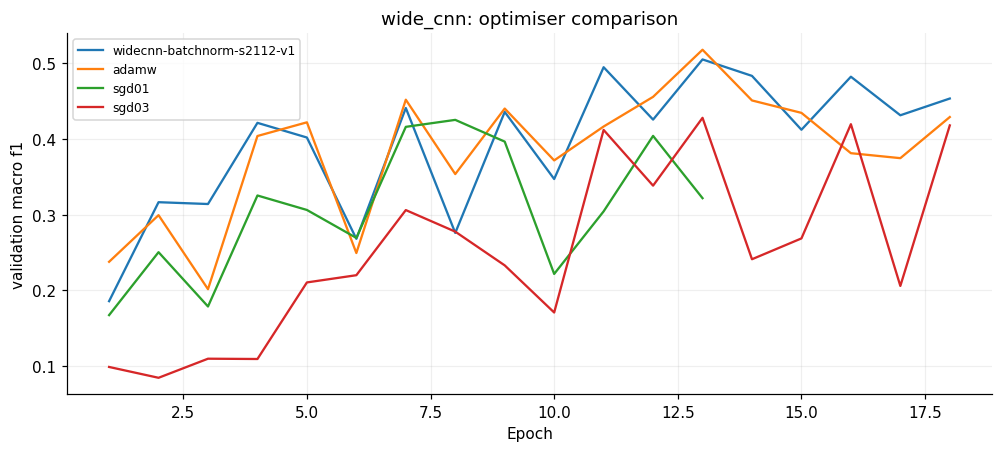

**small_cnn: smallcnn-optimizer-sgd01-s2112-v1** has the highest macro-F1 among this control and completed optimiser trials: **0.5010**, accuracy **69.6%**, missed faults **328/1,492**, normal false alarms **135/1,496**. This is a single-seed validation decision; review the completed epochs and error trade-offs.

**wide_cnn: widecnn-optimizer-adamw-s2112-v1** has the highest macro-F1 among this control and completed optimiser trials: **0.5179**, accuracy **67.8%**, missed faults **137/1,492**, normal false alarms **304/1,496**. This is a single-seed validation decision; review the completed epochs and error trade-offs.

In [20]:
if optimizer_experiments:
    for model in ("small_cnn", "wide_cnn"):
        arms = [r for r in optimizer_controls + optimizer_experiments if r["model"] == model]
        learning_curves(arms, title=f"{model}: optimiser comparison")
    for model in ("small_cnn", "wide_cnn"):
        control = next(r for r in optimizer_controls if r["model"] == model)
        candidates = [control] + [r for r in optimizer_experiments if r["model"] == model]
        winner = max(candidates, key=lambda r: r["metrics"]["macro_f1"])
        m = winner["metrics"]
        display(Markdown(f"**{model}: {winner['run_id']}** has the highest macro-F1 "
                         f"among this control and completed optimiser trials: **{m['macro_f1']:.4f}**, "
                         f"accuracy **{m['accuracy']:.1%}**, missed faults **{m['faults_called_normal']}/1,492**, "
                         f"normal false alarms **{m['normal_called_fault']}/1,496**. "
                         "This is a single-seed validation decision; review the completed epochs and error trade-offs."))


In [21]:
# Overall CNN references after the optimiser follow-up.
# This compares complete configurations, not an isolated optimiser effect.
if optimizer_experiments and search_experiments:
    overall_rows = []
    for model in ("small_cnn", "wide_cnn"):
        candidates = [item for item in search_experiments + optimizer_experiments if item["model"] == model]
        winner = max(candidates, key=lambda item: item["metrics"]["macro_f1"])
        m, s = winner["metrics"], winner["summary"]
        overall_rows.append({"Model": model, "Leading recorded run": winner["run_id"],
            "Macro-F1": m["macro_f1"], "Accuracy": m["accuracy"],
            "Missed faults": m["faults_called_normal"], "Normal false alarms": m["normal_called_fault"],
            "Run status": s["stop_reason"]})
    display(Markdown("**Overall recorded CNN references:** this is a comparison of full configurations. "
                     "It does not attribute depth/activation differences to the optimiser. "
                     "An externally interrupted/recovered checkpoint remains provisional."))
    display(pd.DataFrame(overall_rows).set_index("Model").round(4))


**Overall recorded CNN references:** this is a comparison of full configurations. It does not attribute depth/activation differences to the optimiser. An externally interrupted/recovered checkpoint remains provisional.

,Leading recorded run,Macro-F1,Accuracy,Missed faults,Normal false alarms,Run status
Model,,,,,,
small_cnn,smallcnn-search-bn-depth-s2112-v1,0.5964,0.7413,82,240,max_epochs
wide_cnn,widecnn-search-bn-depth-s2112-v1,0.5500,0.7313,149,179,external_guard_interrupted_then_checkpoint_ver...


## 12. Three-layer SmallCNN follow-up — GELU and training duration

**User-requested budget:** 20 minutes, 17:09:49–17:29:49 Sydney time on 23 October. Focus on the strongest recorded SmallCNN, not a new wide-model search.

The control is **three convolutions (16/32/32 channels), BatchNorm, ReLU, Adam 0.001, class-weighted loss, batch64, seed2112, patience5**. It has 47,820 parameters and reached macro-F1 0.5964 at epoch29 of30. Keep these choices fixed except the declared change:

1. **GELU30:** replace ReLU in the three convolution blocks and hidden classifier, with the same 30-epoch/300-second limits. Hypothesis: the activation improvement seen in a shallower SmallCNN may combine with depth. No extra parameters are introduced.
2. **ReLU60:** permit up to 60 epochs/450 seconds, retaining patience5. Hypothesis: the control's late best epoch suggests additional learning may remain. Compare the first30 epochs with the original run before attributing later gains to the longer allowance.
3. **GELU60:** use the same longer allowance for GELU if its first trial reaches its cap. If GELU30 already early-stops, skip this redundant deterministic repeat; changing an unused maximum cannot change its stopping point.

For these initial activation/duration arms, no optimiser, augmentation, scheduler, width or seed changes are mixed in. No test images are evaluated. Reserve time for checkpoint verification and documentation; unrun or interrupted plans have no claimed completed result.

### Adaptive remaining-budget trials

GELU30 did not beat ReLU and early-stopped; ReLU60 retained the same best epoch29 checkpoint and stopped at34. With time remaining, two separate hypotheses were added:

- **Augmentation30:** compare against ReLU30, adding only training-time horizontal flips (probability0.5) and contrast factors0.9–1.1 (applied with probability0.5). These are assumed label-preserving for the taxonomy, not temperature calibration. Validation and selected-checkpoint training-fit measurements use unchanged images.
- **Gentle60:** compare against ReLU60 with the same patience5/60-epoch policy, adding a plateau scheduler (factor0.5, patience2, threshold0, minimum LR0.00001). It reduces after three non-improving validation-F1 epochs, leaving at least some opportunity before early stopping. Count epochs actually trained at a lower rate, not just reduction events.

These additions are adaptive, not part of the original three-arm list. They run only if their full declared time caps plus reporting reserve fit the same UTC deadline. No new seed checks or test evaluation are introduced.


### Completed outcome and decision

- **GELU30:** macro-F1 0.5802, below the ReLU30 reference0.5964; early-stopped at17. GELU60 was skipped because an identical run with unchanged patience would stop at the same point.
- **ReLU60:** stopped at34, retaining the original best epoch29 and macro-F10.5964. The first30 validation-F1 scores reproduced the reference exactly. Increasing the unused cap alone did not help.
- **Augmentation30:** macro-F10.5680; this mild flip/contrast recipe did not improve the reference under the tested settings.
- **Gentle60:** highest macro-F1 in this follow-up, **0.6012**, with **76.34% accuracy**. However, faults called normal increased from **82 to170**, while normal false alarms fell from **240 to112**. Balanced accuracy fell from **0.6183 to0.5934**. This is a trade-off, not an improvement across all measures.

If missed faults are the priority, retain the earlier ReLU30 checkpoint as a reference. If selecting solely on macro-F1, the gentler schedule is the leading recorded candidate, with a very small gain of0.0048. Do not present that small single-seed validation gain as a reliable general improvement.

A more patient stopping rule was considered but not run: there was insufficient remaining time for its full planned cap plus reporting reserve. No model was fitted after the original trial window; the final record is documentation of the completed runs, not another search.


In [22]:
for arm in ("gelu30", "relu60", "gelu60", "augmentation30", "gentle60"):
    stage = f"small_depth_{arm}"
    filename = f"experiment-plan-smallcnn-depth-{arm}.json"
    PLAN_FILES[stage] = filename
    plans[stage] = json.loads((ROOT / "configs" / filename).read_text())
# run_experiment("small_depth_gelu30")              # smoke only
# run_experiment("small_depth_gelu30", full=True)   # refuses existing run IDs

small_followup_path = ROOT / "results/smallcnn-20min-v1.json"
small_followup_trials = []
if small_followup_path.is_file():
    small_followup = json.loads(small_followup_path.read_text())
    assert small_followup["test_evaluated"] is False
    small_followup_control = small_followup["control"]
    small_followup_trials = small_followup["experiments"]
    followup_rows = []
    for label, result in [("ReLU30 reference", small_followup_control)] + [(r["arm"], r) for r in small_followup_trials]:
        m, s = result["metrics"], result["summary"]
        followup_rows.append({"Arm": label, "Epochs / best": f"{s['epochs_completed']} / {s['best_epoch']}",
            "Macro-F1": m["macro_f1"], "Accuracy": m["accuracy"], "Balanced accuracy": m["balanced_accuracy"],
            "Missed faults": m["faults_called_normal"], "Normal false alarms": m["normal_called_fault"], "Stop": s["stop_reason"]})
    display(pd.DataFrame(followup_rows).set_index("Arm").round(4))
    display(pd.DataFrame([{key: t.get(key) for key in ("arm", "status")}
                          for t in small_followup["ledger"]["trials"]]).set_index("arm"))
else:
    print("Follow-up pending: no new result claimed.")


,Epochs / best,Macro-F1,Accuracy,Balanced accuracy,Missed faults,Normal false alarms,Stop
Arm,,,,,,,
ReLU30 reference,30 / 29,0.5964,0.7413,0.6183,82,240,max_epochs
gelu30,17 / 12,0.5802,0.7470,0.5822,177,121,early_stopping
relu60,34 / 29,0.5964,0.7413,0.6183,82,240,early_stopping
augmentation30,19 / 14,0.5680,0.7423,0.5723,209,134,early_stopping
gentle60,28 / 23,0.6012,0.7634,0.5934,170,112,early_stopping


,status
arm,
gelu30,completed
relu60,completed
gelu60,not_run_redundant_early_stopping
augmentation30,completed
gentle60,completed


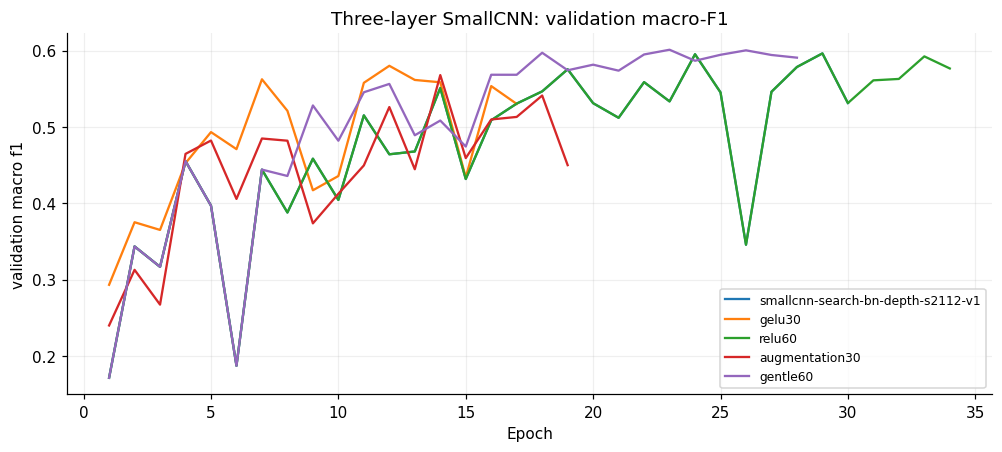

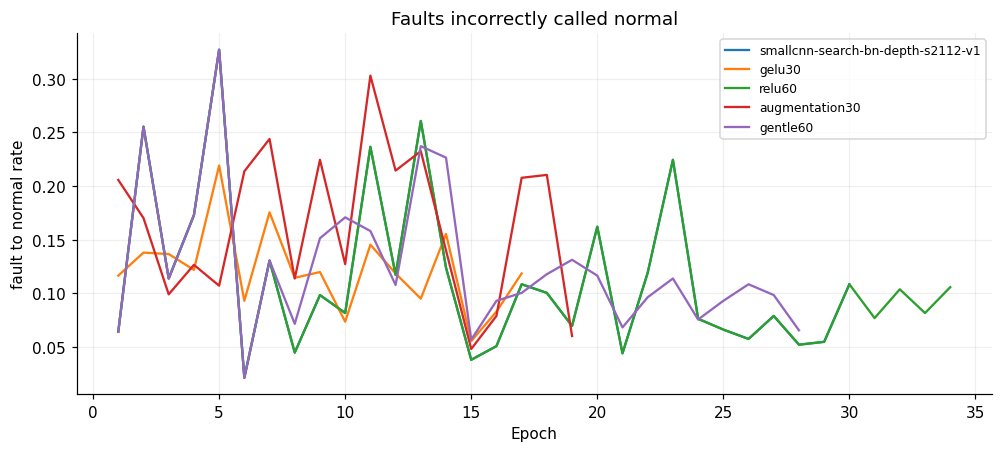

**Leading configuration in this follow-up:** `smallcnn-depth-gentle60-s2112-v1` — macro-F1 **0.6012**, accuracy **76.3%**, missed faults **170/1,492**, normal false alarms **112/1,496**. This is validation-selected evidence at one seed; inspect the full error trade-off.

ReLU60 first30 validation F1 values match the reference exactly: True


Detailed record: [SmallCNN GELU/duration report](../results/smallcnn-20min-v1.md).

In [23]:
if small_followup_trials:
    arms = [small_followup_control] + small_followup_trials
    learning_curves(arms, title="Three-layer SmallCNN: validation macro-F1")
    learning_curves(arms, title="Faults incorrectly called normal", key="fault_to_normal_rate")
    small_followup_winner = max([small_followup_control] + small_followup_trials, key=lambda r: r["metrics"]["macro_f1"])
    m = small_followup_winner["metrics"]
    display(Markdown(f"**Leading configuration in this follow-up:** `{small_followup_winner['run_id']}` — "
                     f"macro-F1 **{m['macro_f1']:.4f}**, accuracy **{m['accuracy']:.1%}**, "
                     f"missed faults **{m['faults_called_normal']}/1,492**, normal false alarms **{m['normal_called_fault']}/1,496**. "
                     "This is validation-selected evidence at one seed; inspect the full error trade-off."))
    for result in small_followup_trials:
        if "control_prefix_matches" in result:
            print("ReLU60 first30 validation F1 values match the reference exactly:", result["control_prefix_matches"])
    display(Markdown("Detailed record: [SmallCNN GELU/duration report](../results/smallcnn-20min-v1.md)."))


## 13. Consolidated error review and baseline conclusions

The experiments above are a chronological development record. **Pause further baseline tuning here.** Retain two references: the three-layer BatchNorm/ReLU SmallCNN has fewer faults called normal (**82**); adding the gentler scheduler gives the highest macro-F1 (**0.6012**) but calls **170** faults normal. Its reduction in normal false alarms (**240 → 112**) explains part of this trade-off. Neither is better on every measure.

The tables below compare per-class F1/recall and common directional confusions on the original validation partition. Rows in the plots are true classes; columns are predictions; each row sums to 100%. Normalisation lets rare classes remain visible. The earlier section 8 describes the earlier two-layer controls, not these final references.

No new fitting or test inference is performed in this review. Small class supports and repeated validation-based selection limit confidence in small improvements.


Fewer missed faults: smallcnn-search-bn-depth-s2112-v1


,Validation images,precision,recall,f1
Soiling,31.0,0.250,0.419,0.313
Hot-Spot,37.0,0.469,0.405,0.435
Cell-Multi,193.0,0.476,0.409,0.440
Offline-Module,123.0,0.392,0.634,0.484
Shadowing,156.0,0.441,0.699,0.541
Hot-Spot-Multi,37.0,0.594,0.514,0.551
Cell,280.0,0.612,0.632,0.622
Cracking,141.0,0.669,0.603,0.634
Vegetation,245.0,0.625,0.702,0.662
Diode-Multi,26.0,0.667,0.692,0.679


,Images,True class,Predicted class
0,93,No-Anomaly,Shadowing
1,88,No-Anomaly,Offline-Module
2,38,Cell-Multi,Cell
3,35,Vegetation,Cell
4,32,Cell,Vegetation
5,28,Cell,Cell-Multi
6,27,Offline-Module,No-Anomaly
7,25,Cell-Multi,Vegetation


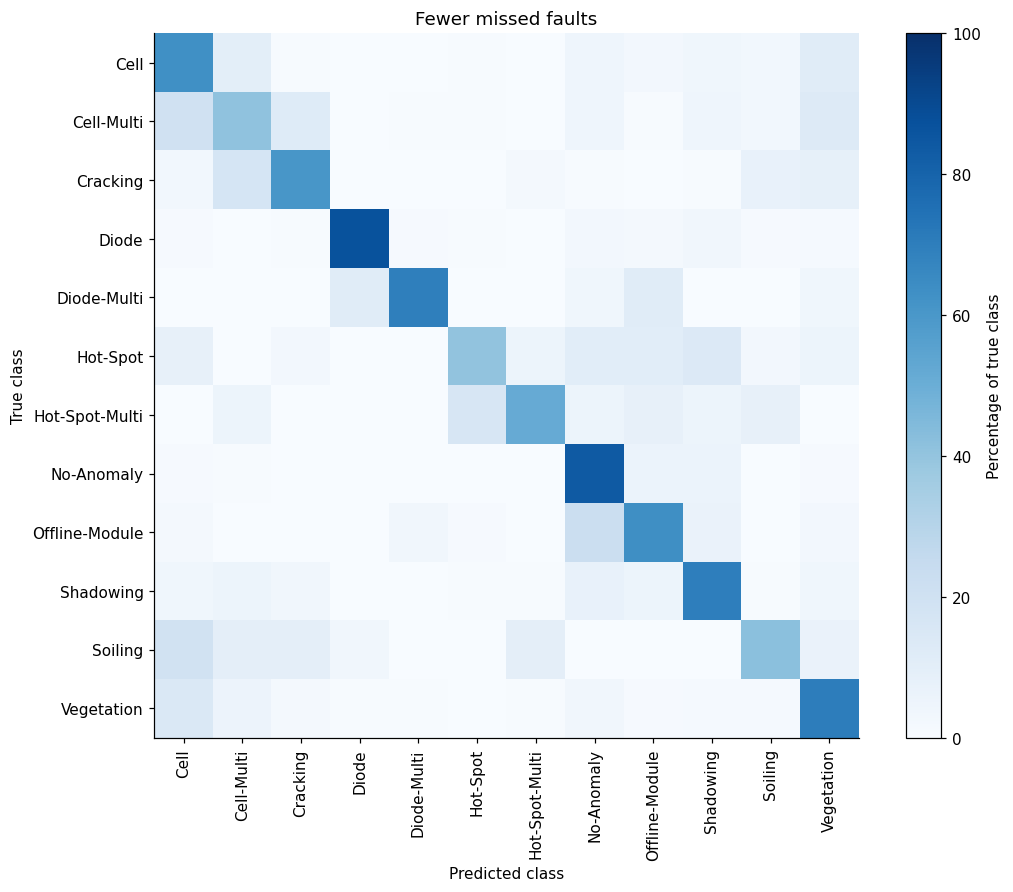

Highest macro-F1: smallcnn-depth-gentle60-s2112-v1


,Validation images,precision,recall,f1
Soiling,31.0,0.355,0.355,0.355
Cell-Multi,193.0,0.487,0.383,0.429
Hot-Spot,37.0,0.391,0.486,0.434
Offline-Module,123.0,0.569,0.472,0.516
Shadowing,156.0,0.553,0.538,0.545
Hot-Spot-Multi,37.0,0.537,0.595,0.564
Cell,280.0,0.583,0.643,0.611
Cracking,141.0,0.647,0.610,0.628
Vegetation,245.0,0.664,0.629,0.646
Diode-Multi,26.0,0.800,0.615,0.696


,Images,True class,Predicted class
0,52,Cell-Multi,Cell
1,49,Offline-Module,No-Anomaly
2,44,Vegetation,Cell
3,38,Shadowing,No-Anomaly
4,31,No-Anomaly,Offline-Module
5,30,No-Anomaly,Shadowing
6,28,Cell,Vegetation
7,26,Cell-Multi,Cracking


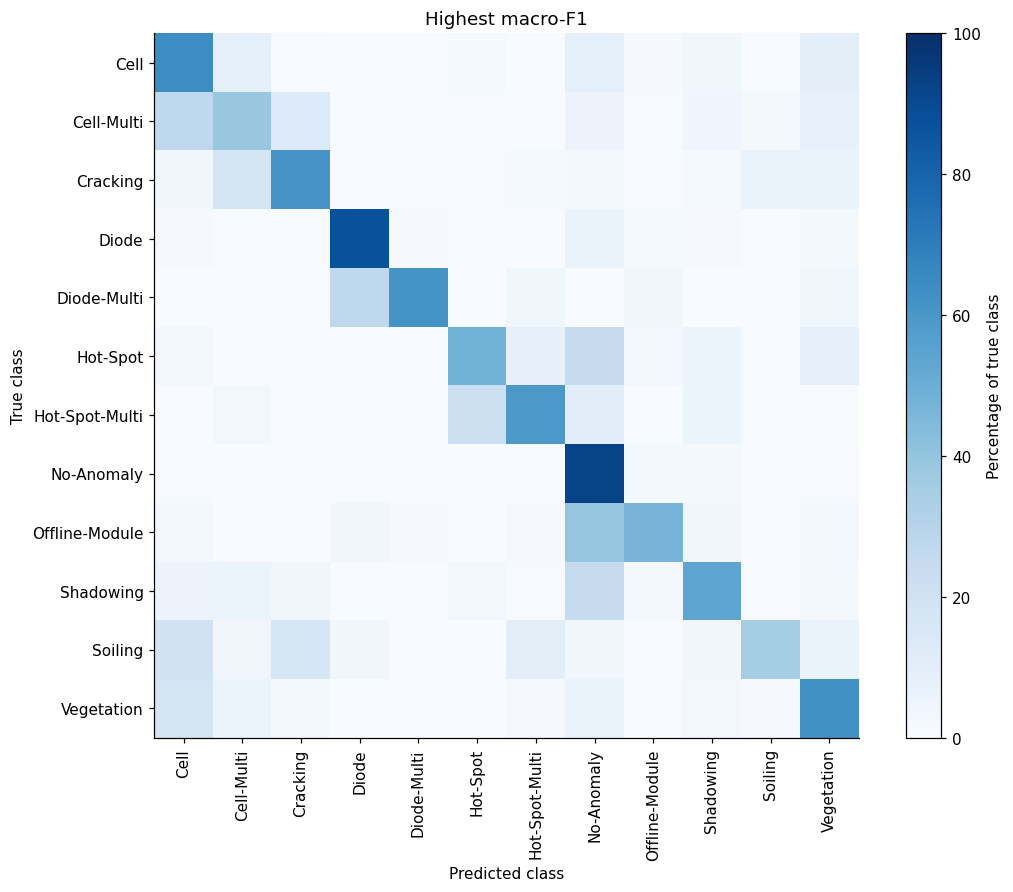

In [24]:
error_review = json.loads((ROOT / "results/cnn-error-review-v1.json").read_text())
review_labels = error_review["class_names"]
for result in error_review["models"]:
    m = result["metrics"]
    print(f"{result['role']}: {result['run_id']}")
    display(pd.DataFrame(m["per_class"]).T.rename(columns={"support": "Validation images"})
            .sort_values("f1").round(3))
    display(pd.DataFrame(result["top_confusions"]).rename(columns={
        "true_label": "True class", "predicted_label": "Predicted class", "count": "Images"}))
    confusion_matrix(m, result["role"])


### Inspect examples of the three kinds of error

For each reference, show one **missed fault**, one **normal false alarm**, and one **wrong fault type**. Selection is deterministic: the lowest image ID in each category, rather than choosing visually dramatic cases. These examples illustrate errors; they do not estimate their frequency or establish their causes. Image brightness uses the same fixed 0–1 scale for every panel. If local data are absent, the captions and metrics still work.


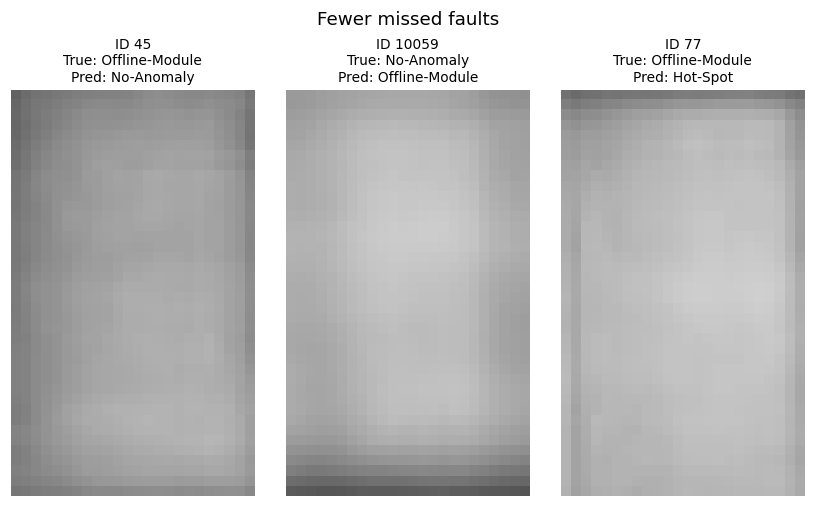

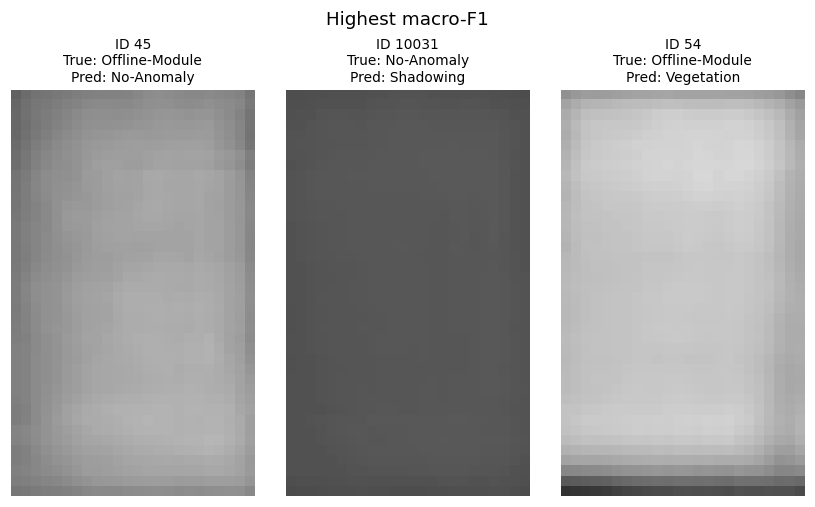

In [25]:
for result in error_review["models"]:
    image_examples(result["examples"], ROOT / "data/raw", result["role"])


### Decision and next phase

- **Retain both SmallCNN references:** macro-F1 alone would hide the increase in missed faults. Their checkpoint IDs and full metric tables are saved in `results/cnn-error-review-v1.json`.
- **Keep the task as 12-class classification:** recognising that a panel is anomalous is useful, but predicting the wrong fault type is still a classification error.
- **Treat rare-class weaknesses as unresolved:** inspect class-specific evidence before attributing mistakes to model capacity, data scarcity or label ambiguity. The plots do not prove any of these causes.
- **Additional seeds remain deferred:** the current results come from seed 2112 and repeated selection on one validation partition. They do not establish a reliable improvement across runs or unseen sites.
- **Move to the separate ResNet notebook:** compare using the same split and measures, preserving these baseline results. Reserve the original test set for a final evaluation after model choices are frozen.

The full training entry point, configurations, result snapshots and this notebook belong to branch `feature/cnn-training-comparison`. Raw data, virtual environments, checkpoints and full run outputs stay outside Git.
